# Week 6 — Walk-forward volatility forecasting
Grace | RGBFS

Compare persistence, HAR-style OLS and volatility-plus-cluster OLS on common forecast dates. Forecasts are made after market close. The target is annualized realized SPY volatility over the next 20 trading days. The expanding-window design is proposed, pending team confirmation.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
HERE = Path.cwd().resolve()
ROOT = next(p for p in (HERE, *HERE.parents) if (p/'notebooks').is_dir() and (p/'data').is_dir())
OUT = ROOT/'notebooks/outputs/grace_week6'
OUT.mkdir(parents=True, exist_ok=True)
INITIAL = 1260
STEP = 20
VOL = ['vol_5','vol_20','vol_60']
CLUSTER = ['n_stocks','n_nodes','n_edges','density','n_communities','modularity','largest_share','stability']
MODELS = ['Persistence','HAR-style','Volatility + clusters']
print(ROOT, OUT, sep='\n')

C:\Users\dayan\Downloads\RGBFS
C:\Users\dayan\Downloads\RGBFS\notebooks\outputs\grace_week6


### Interpretation — configuration
The project paths resolved successfully and the output directory is `notebooks/outputs/grace_week6`. The experiment retains the Week 5 annualized SPY volatility target, $y_t=\sqrt{(252/20)\sum_{j=1}^{20}r_{t+j}^2}$, so differences in evaluation do not arise from redefining the target. Persistence uses `vol_20`; HAR-style ordinary least squares uses `vol_5`, `vol_20`, and `vol_60`; the enhanced OLS adds eight market-adjusted network features. These represent network size, connectivity, community count, modularity, concentration and stability. The 1,260-observation initial training minimum and 20-observation refit cadence are proposed choices rather than confirmed team requirements.

## 2. Load and audit Week 5 dataset
Reuse the existing target rather than recomputing it. Cluster dates must not be later than forecast dates. Same-day availability is assumed and must be confirmed with the team.

In [2]:
df = pd.read_csv(ROOT/'notebooks/outputs/grace_week5/forecasting_dataset.csv', parse_dates=['date','target_end','cluster_date']).sort_values('date').reset_index(drop=True)
assert not df.date.duplicated().any()
assert not df[['date','target_end','cluster_date','target',*VOL,*CLUSTER]].isna().any().any()
assert np.isfinite(df[['target',*VOL,*CLUSTER]].to_numpy()).all()
assert (df.target_end > df.date).all()
assert (df.cluster_date <= df.date).all()
print('Shape:', df.shape, 'Date range:', df.date.min(), df.date.max())
display(df.head())

Shape: (5371, 15) Date range: 2005-05-25 00:00:00 2026-09-30 00:00:00


,date,vol_5,vol_20,vol_60,target,target_end,cluster_date,n_stocks,n_nodes,n_edges,density,n_communities,modularity,largest_share,stability
0,2005-05-25,0.053354,0.114519,0.121049,0.075013,2005-06-23,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
1,2005-05-26,0.058324,0.107218,0.121542,0.077098,2005-06-24,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
2,2005-05-27,0.058644,0.095968,0.121587,0.077039,2005-06-27,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
3,2005-05-31,0.062914,0.096586,0.119599,0.079410,2005-06-28,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897
4,2005-06-01,0.085765,0.101045,0.120868,0.074007,2005-06-29,2005-05-25,263.0,263.0,1723.0,0.05001,6.0,0.581243,0.311787,0.385897


### Interpretation — data quality and feature timing
The complete forecasting panel contains **5,371 rows and 15 columns**, from May 25, 2005 through September 30, 2026. The successful assertions establish unique forecast dates, complete and finite predictors and targets, future target end dates, and cluster dates no later than forecast origins. For example, the first row uses a May 25, 2005 cluster observation and has a target ending June 23, 2005. Reusing the Week 5 panel preserves consistency across experiments. These checks establish date ordering, but cannot independently establish whether upstream clustering data were genuinely available after market close on each recorded date or whether upstream construction was free of leakage.

## 3. Expanding walk-forward framework
Train only on targets whose end dates precede the first forecast date in each block. This conservative rule prevents unavailable outcomes entering training. Refit every 20 observations; predictors update daily. The initial training set contains at least 1,260 matured targets.

In [3]:
first = next(i for i in range(INITIAL,len(df)) if (df.target_end < df.date.iloc[i]).sum() >= INITIAL)
rows=[]
for fold, start in enumerate(range(first,len(df),STEP),1):
    test=df.iloc[start:start+STEP].copy()
    origin=test.date.iloc[0]
    train=df.loc[(df.date < origin)&(df.target_end < origin)]
    assert len(train)>=INITIAL and train.target_end.max()<origin
    test['Persistence']=test.vol_20
    for name,cols in [('HAR-style',VOL),('Volatility + clusters',VOL+CLUSTER)]:
        model=LinearRegression().fit(train[cols],train.target)
        test[name]=model.predict(test[cols])
    test['fold']=fold
    test['train_n']=len(train)
    test['train_target_end_max']=train.target_end.max()
    rows.append(test)
pred=pd.concat(rows,ignore_index=True)
assert not pred.date.duplicated().any()
assert (pred.train_target_end_max < pred.date).all()
print('Folds:',pred.fold.nunique(),'Forecasts:',len(pred),'Range:',pred.date.min(),pred.date.max())
display(pred[['date','target',*MODELS,'fold','train_n']].head())

Folds: 205 Forecasts: 4091 Range: 2010-06-25 00:00:00 2026-09-30 00:00:00


,date,target,Persistence,HAR-style,Volatility + clusters,fold,train_n
0,2010-06-25,0.232411,0.241987,0.208316,0.205423,1,1260
1,2010-06-28,0.232142,0.238115,0.206978,0.204303,1,1260
2,2010-06-29,0.205921,0.255232,0.247408,0.240245,1,1260
3,2010-06-30,0.203876,0.240286,0.245187,0.238271,1,1260
4,2010-07-01,0.203263,0.240495,0.234370,0.228181,1,1260


### Interpretation — walk-forward execution
The expanding-window framework produced **205 folds and 4,091 forecasts per model**, from June 25, 2010 through September 30, 2026. The first fold uses 1,260 matured training targets. Each subsequent block refits the two OLS models using all eligible historical observations; persistence requires no fitting. Coefficients remain fixed within each block, while predictors update at each daily forecast origin. The strict rule `target_end < origin` excludes training labels that have not matured before the block starts, and the final assertions verify unique forecast dates and training-label timing. All models forecast the same dates. Because the horizon is 20 trading days and forecasts are daily, adjacent outcomes overlap; the 4,091 forecasts should not be treated as independent observations.

## 4. Model comparison
MAE and RMSE are in annualized volatility units (multiply by 100 for percentage points). R² uses the evaluated sample mean as its reference. Negative R² is possible. OLS forecasts are not clipped, to preserve the stated model specification.

In [4]:
def metrics(g):
    return pd.DataFrame([dict(model=m,n=len(g),MAE=mean_absolute_error(g.target,g[m]),RMSE=np.sqrt(mean_squared_error(g.target,g[m])),R2=r2_score(g.target,g[m]) if len(g)>1 and g.target.nunique()>1 else np.nan) for m in MODELS])
comparison=metrics(pred).sort_values('RMSE').reset_index(drop=True)
fold_metrics=pd.concat([metrics(g).assign(fold=k,start=g.date.min(),end=g.date.max()) for k,g in pred.groupby('fold')],ignore_index=True)
annual=pd.concat([metrics(g).assign(year=k) for k,g in pred.groupby(pred.date.dt.year)],ignore_index=True)
display(comparison)
print('Negative forecasts:', (pred[MODELS]<0).sum().to_dict())

,model,n,MAE,RMSE,R2
0,HAR-style,4091,0.046569,0.075116,0.283343
1,Volatility + clusters,4091,0.052376,0.083755,0.109026
2,Persistence,4091,0.052027,0.086887,0.041159


Negative forecasts: {'Persistence': 0, 'HAR-style': 0, 'Volatility + clusters': 33}


### Interpretation — overall and temporal model comparison
| Model | Forecasts | MAE | RMSE | R² |
|---|---:|---:|---:|---:|
| Persistence | 4,091 | 0.052027 | 0.086887 | 0.041159 |
| HAR-style | 4,091 | 0.046569 | 0.075116 | 0.283343 |
| Volatility + clusters | 4,091 | 0.052376 | 0.083755 | 0.109026 |

HAR ranks first on all three metrics. Its RMSE of 0.075116 corresponds to 7.5116 annualized volatility percentage points and is 13.55% lower than persistence. Adding cluster predictors increases RMSE by 11.50% relative to HAR; the enhanced model nonetheless beats persistence on RMSE, but not MAE. R² measures squared-error improvement against the evaluated sample mean, not against an implementable real-time mean forecast. The enhanced model produces 33 negative forecasts (about 0.81%); the other models produce none. These physically invalid forecasts are retained to preserve the original OLS experiment. Fold and year metrics support temporal diagnostics; the pooled metrics above, rather than an unweighted average of fold RMSEs, are the primary comparison.

## 5. Retrospective stress analysis
Use stress status at forecast origin only for descriptive grouping, never as a predictor. Centered labels may use future information. Missing labels remain unknown; they are not treated as normal days.

In [5]:
stress=pd.read_parquet(ROOT/'data/processed/stress_labels_daily.parquet')[['stress']].copy()
stress.index=pd.to_datetime(stress.index)
assert not stress.index.duplicated().any()
pred=pred.merge(stress.rename_axis('date').reset_index(),on='date',how='left',validate='one_to_one')
print('Stress label counts:',pred.stress.value_counts(dropna=False))
parts=[metrics(g).assign(stress=k) for k,g in pred.dropna(subset=['stress']).groupby('stress')]
stress_metrics=pd.concat(parts,ignore_index=True) if parts else pd.DataFrame(columns=['model','n','MAE','RMSE','R2','stress'])
display(stress_metrics)

Stress label counts: stress
0.0    3715
1.0     376
Name: count, dtype: int64


,model,n,MAE,RMSE,R2,stress
0,Persistence,3715,0.043383,0.061482,-0.237906,0.0
1,HAR-style,3715,0.039702,0.054348,0.032704,0.0
2,Volatility + clusters,3715,0.046222,0.065579,-0.408403,0.0
3,Persistence,376,0.137429,0.211638,-0.818829,1.0
4,HAR-style,376,0.114413,0.179467,-0.307899,1.0
5,Volatility + clusters,376,0.113181,0.183938,-0.373868,1.0


### Interpretation — financial stress
The retrospective stress merge classifies all 4,091 forecast origins: 3,715 normal (90.81%) and 376 stress (9.19%).

| Model | Normal MAE | Normal RMSE | Stress MAE | Stress RMSE |
|---|---:|---:|---:|---:|
| Persistence | 0.043383 | 0.061482 | 0.137429 | 0.211638 |
| HAR-style | 0.039702 | 0.054348 | 0.114413 | 0.179467 |
| Volatility + clusters | 0.046222 | 0.065579 | 0.113181 | 0.183938 |

HAR leads on both errors in normal markets and on RMSE during stress. The enhanced model has approximately 1.08% lower stress MAE than HAR, but its stress RMSE is higher. All stress-period R² values are negative (persistence −0.818829, HAR −0.307899, enhanced −0.373868). Forecasts are substantially harder during stress. The small MAE improvement motivates further investigation but does not establish statistical significance or support a deployable stress-switching rule: labels are retrospective and describe the forecast origin rather than the entire future target window.

## 6. Visualizations

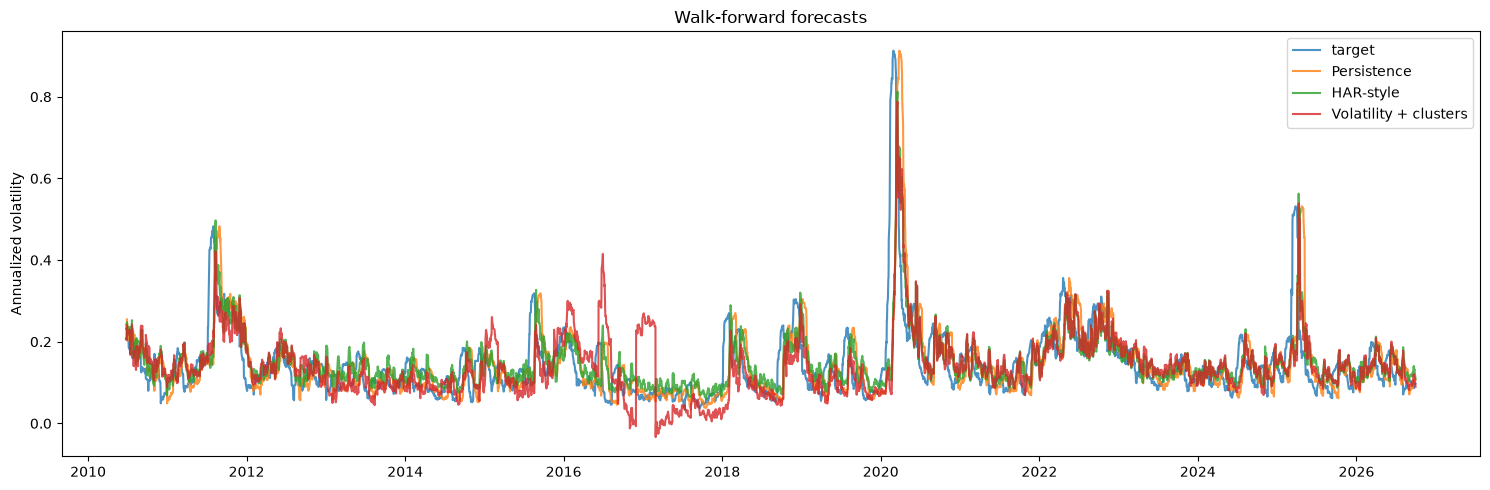

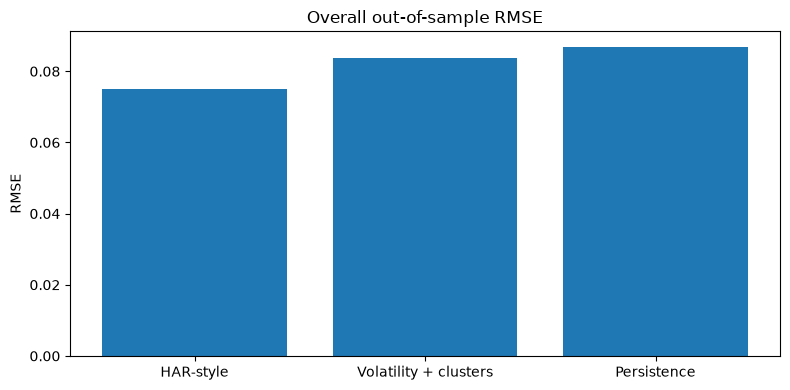

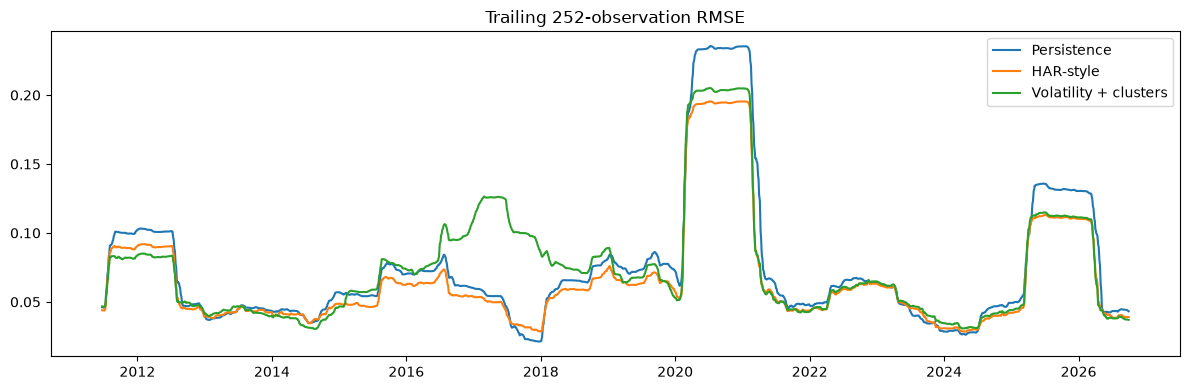

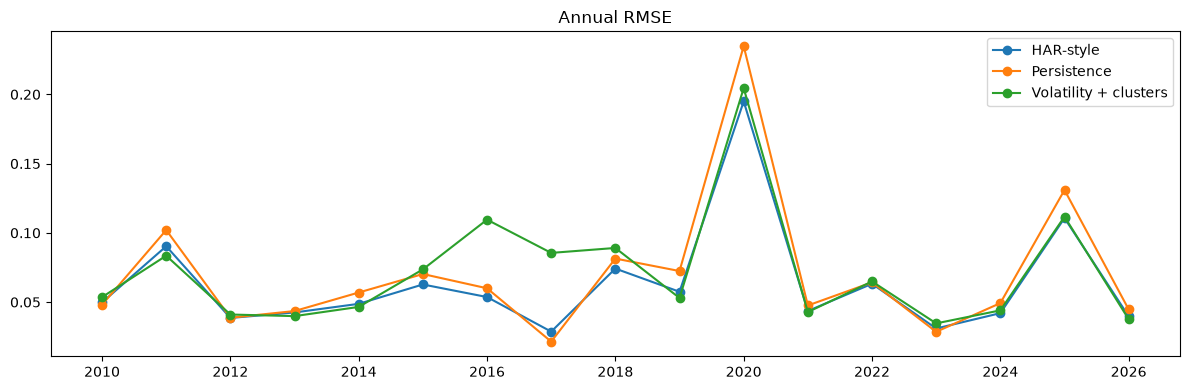

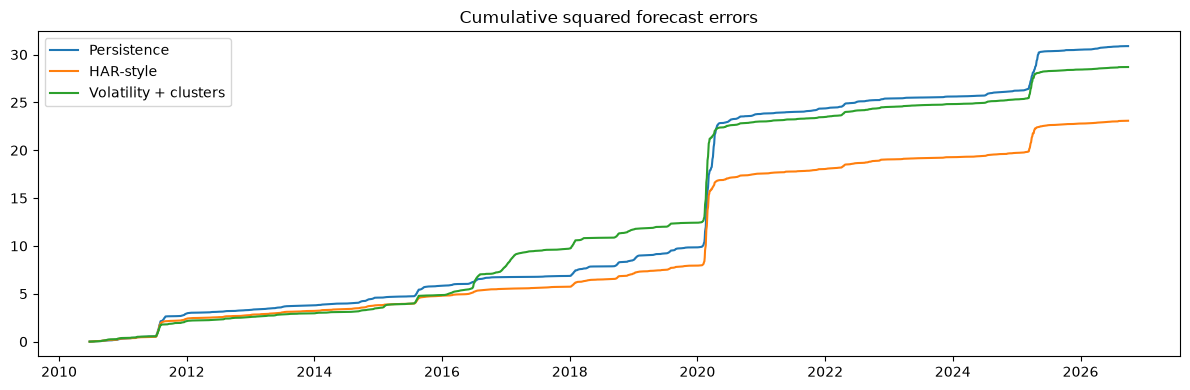

In [6]:
def save(name):
    plt.tight_layout(); plt.savefig(OUT/name,dpi=150,bbox_inches='tight'); plt.show(); plt.close()
plt.figure(figsize=(15,5))
for m in ['target',*MODELS]: plt.plot(pred.date,pred[m],label=m,alpha=.8)
plt.ylabel('Annualized volatility'); plt.title('Walk-forward forecasts'); plt.legend(); save('walk_forward_forecasts.png')
plt.figure(figsize=(8,4)); plt.bar(comparison.model,comparison.RMSE); plt.ylabel('RMSE'); plt.title('Overall out-of-sample RMSE'); save('model_rmse_comparison.png')
plt.figure(figsize=(12,4))
for m in MODELS: plt.plot(pred.date,((pred[m]-pred.target)**2).rolling(252,min_periods=252).mean().pow(.5),label=m)
plt.title('Trailing 252-observation RMSE'); plt.legend(); save('rolling_model_performance.png')
plt.figure(figsize=(12,4))
for m,g in annual.groupby('model'): plt.plot(g.year,g.RMSE,marker='o',label=m)
plt.title('Annual RMSE'); plt.legend(); save('annual_model_performance.png')
plt.figure(figsize=(12,4))
for m in MODELS: plt.plot(pred.date,((pred[m]-pred.target)**2).cumsum(),label=m)
plt.title('Cumulative squared forecast errors'); plt.legend(); save('cumulative_forecast_errors.png')

### Interpretation — figures
1. **Walk-forward forecasts:** compares realized and predicted annualized volatility on common dates; inspect the response to volatility spikes and possible lag in predictions. Values are plotted at forecast origins even though the targets become known later.
2. **Overall RMSE:** confirms HAR has the lowest pooled RMSE, followed by the enhanced model and persistence.
3. **Trailing 252-observation RMSE:** shows how forecasting accuracy changes over time; early values are absent until 252 errors are accumulated. Because targets mature later, the plotted statistic is retrospective, not a real-time signal.
4. **Annual RMSE:** allows comparison by calendar year of forecast origin; 2010 and 2026 have partial coverage and annual sample sizes may differ.
5. **Cumulative squared errors:** the final ranking matches pooled RMSE because models share the same observations. Steep increases indicate periods of larger squared errors; the curves cannot decrease. None of the plots establishes statistical significance.

## 7. Export results

In [7]:
for name,table in [('model_comparison_results',comparison),('walk_forward_predictions',pred),('walk_forward_fold_metrics',fold_metrics),('annual_model_performance',annual),('stress_period_performance',stress_metrics)]:
    table.to_csv(OUT/f'{name}.csv',index=False)
print('Saved files:')
for p in sorted(OUT.iterdir()): print(p.name)

Saved files:
annual_model_performance.csv
annual_model_performance.png
cumulative_forecast_errors.png
model_comparison_results.csv
model_rmse_comparison.png
rolling_model_performance.png
stress_period_performance.csv
walk_forward_fold_metrics.csv
walk_forward_forecasts.png
walk_forward_predictions.csv


### Interpretation — reproducibility and deliverables
The saved-file output lists five CSV tables and five PNG figures. `model_comparison_results.csv` is the primary required deliverable. `walk_forward_predictions.csv` records forecast dates, realized targets, predictions, fold identifiers and training-label timing for audit. `walk_forward_fold_metrics.csv`, `annual_model_performance.csv` and `stress_period_performance.csv` support robustness diagnostics. The five figures complement these tables. Outputs reside in the Week 6 directory, leaving the Week 5 source dataset unchanged.

## 8. Results interpretation and conclusion
The following cell generates the conclusion from actual results, not assumed model rankings.

In [8]:
scores=comparison.set_index('model').RMSE
best=scores.idxmin()
change=100*(scores['Volatility + clusters']/scores['HAR-style']-1) if scores['HAR-style']>0 else np.nan
print(f'Lowest overall RMSE: {best} ({scores[best]:.6f}).')
print(f'Cluster model RMSE change relative to HAR: {change:+.2f}%.')
print('A negative change indicates improvement; a positive change indicates deterioration.')
print('All models were evaluated on the same dates with matured training targets only.')

Lowest overall RMSE: HAR-style (0.075116).
Cluster model RMSE change relative to HAR: +11.50%.
A negative change indicates improvement; a positive change indicates deterioration.
All models were evaluated on the same dates with matured training targets only.


### Interpretation — relationship to Week 5
Week 6 confirms the Week 5 ranking by RMSE: HAR remains the preferred baseline, and adding clustering features does not improve overall accuracy for the tested linear specification. Week 5 test R² values were negative, whereas the Week 6 pooled R² values are positive. These evaluations cover different periods, so this difference cannot be attributed solely to regular retraining. A matched-date comparison would be needed to isolate that effect. Redundant network predictors and changing market relationships are plausible explanations for the enhanced model's performance, not established causes.

## 9. Limitations
Overlapping 20-day targets yield dependent errors; metric differences are descriptive, not significance tests. Stress labels are retrospective. Cluster availability and upstream construction must be audited independently. Initial training length and refit cadence are proposed settings. The evaluation includes dates used in Week 5 development and is not a fresh untouched holdout. Annual results group by forecast origin, and partial years are not directly comparable in coverage. Confirm the three model specifications and walk-forward protocol with the team before final submission.

### Additional limitations and next steps
The unconstrained enhanced OLS model generates negative volatility forecasts; future experiments could prespecify a nonnegative or log-target model, or ridge regression to address correlated predictors. Any tuning should occur inside a chronological validation procedure, not on the reported evaluation outcomes. Assess uncertainty using methods that account for overlapping forecast horizons, and test alternatives on a genuinely untouched period. Confirm point-in-time feature construction, model definitions and evaluation settings with the team before treating these findings as final evidence.

## 10. Final conclusion
Week 6 fulfilled the two technical assignments: all three forecasting models were evaluated through an expanding walk-forward framework, and the model comparison results table was generated. Across 205 folds and 4,091 common forecast dates, the HAR-style model achieved the lowest MAE (0.046569), lowest RMSE (0.075116), and highest R² (0.283343). It reduced RMSE by 13.55% relative to persistence. Adding clustering features increased RMSE by 11.50% compared with HAR, so the tested enhanced model does not demonstrate overall incremental predictive value. During retrospectively identified financial stress, the enhanced model delivered slightly lower MAE but higher RMSE than HAR, a qualified finding suitable for further research. Its 33 negative forecasts also reveal a limitation of unconstrained regression.

The recommended baseline for the team's subsequent experiments is HAR-style regression using historical volatility alone. Network features remain candidates for future, prespecified experiments rather than proven improvements. The comparison table and supporting outputs provide a reproducible basis for the team's discussion, subject to confirmation of the proposed protocol and upstream feature availability.